In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pprint
import sys
np.set_printoptions(suppress=True, linewidth=200, threshold=1000000, precision=3)
from google.colab import drive
original_limit = sys.maxsize

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path='/content/drive/MyDrive/Science_Fair_Data_2025-2026/ConsolidatedCSV.csv'
df=pd.read_csv(path)
df

,Substance,Laser_Intenstity,Concentration,194.1151,196.1586,198.2017,200.2442,202.2863,204.3278,206.3688,...,3357.1519,3358.3602,3359.5684,3360.7764,3361.9843,3363.1921,3364.3998,3365.6074,3366.8148,3368.0221
0,Water,0.35,0.00000,204.7,204.7,204.7,204.7,204.7,204.7,204.7,...,7.8,4.9,3.1,-8.5,5.0,4.4,6.2,5.2,5.2,5.2
1,Water,0.40,0.00000,404.4,404.4,404.4,404.4,404.4,404.4,404.4,...,9.9,-0.5,3.1,0.8,4.2,3.8,2.9,6.0,6.0,6.0
2,Water,0.45,0.00000,607.3,607.3,607.3,607.3,607.3,607.3,607.3,...,15.6,13.8,9.9,10.2,18.2,15.3,17.0,6.2,6.2,6.2
3,Water,0.50,0.00000,866.9,866.9,866.9,866.9,866.9,866.9,866.9,...,17.7,18.7,20.2,21.8,24.7,23.7,19.4,14.3,14.3,14.3
4,Water,0.55,0.00000,1122.4,1122.4,1122.4,1122.4,1122.4,1122.4,1122.4,...,25.8,26.6,29.8,24.4,28.7,26.6,26.7,30.9,30.9,30.9
5,Water,0.60,0.00000,1314.5,1314.5,1314.5,1314.5,1314.5,1314.5,1314.5,...,25.3,23.6,30.7,30.0,24.4,17.1,22.8,25.7,25.7,25.7
6,Water,0.65,0.00000,1582.6,1582.6,1582.6,1582.6,1582.6,1582.6,1582.6,...,39.0,45.6,44.9,47.3,40.9,36.9,41.9,36.1,36.1,36.1
7,Water,0.70,0.00000,1841.4,1841.4,1841.4,1841.4,1841.4,1841.4,1841.4,...,49.8,50.4,50.4,41.9,42.5,45.1,51.5,60.8,60.8,60.8
8,T4 in Water,0.35,0.00021,180.3,180.3,180.3,180.3,180.3,180.3,180.3,...,7.6,8.7,5.6,4.8,5.6,-0.4,5.1,5.1,5.1,5.1
9,T4 in Water,0.40,0.00021,362.7,362.7,362.7,362.7,362.7,362.7,362.7,...,18.7,12.0,9.6,15.3,11.2,7.6,2.1,-0.8,-0.8,-0.8


In [ ]:
# Define Predictors and Target Variable
X = df.iloc[:, 1:].to_numpy()       # iloc selects data by index
y = df.loc[:, 'Substance'].to_numpy()

# Splitting Data into Training Set and Test Set
from sklearn.model_selection import train_test_split
testsize = 0.3
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=testsize, stratify=y, random_state=0)

# Standardizing data
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(X_train)
X_train_std = sc.transform(X_train)
X_test_std = sc.transform(X_test)

from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(C=10, solver='liblinear', multi_class='ovr')
lr = lr.fit(X_train_std, y_train)
lr.fit(X_train_std, y_train)
print("Training accuracy: ", lr.score(X_train_std, y_train))
print("Test accuracy: ", lr.score(X_test_std, y_test))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


Training accuracy:  1.0
Test accuracy:  0.46153846153846156


**PCA Analysis**

In [ ]:
from sklearn.decomposition import PCA
pca = PCA()
pca.fit(X_train_std)

ev = pca.explained_variance_ratio_

with np.printoptions(precision=3):
    print('Fraction of variance explained by each PC =', ev)
    print('Cumulative fraction of variance explained =', np.cumsum(ev))


Fraction of variance explained by each PC = [0.889 0.099 0.006 0.001 0.001 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.   ]
Cumulative fraction of variance explained = [0.889 0.988 0.994 0.995 0.996 0.996 0.997 0.997 0.997 0.998 0.998 0.998 0.998 0.998 0.998 0.999 0.999 0.999 0.999 0.999 0.999 0.999 0.999 1.    1.    1.    1.    1.    1.    1.   ]


In [45]:
pcalist = ( np.c_[np.round(pca.components_[0],2), df.columns[1:]] )
#pcalist.sort(key=lambda item: item[0], reverse=True)
pprint.pprint(pcalist)

array([[0.01, 'Laser_Intenstity'],
       [0.02, 'Concentration'],
       [0.02, '194.1151'],
       [0.02, '196.1586'],
       [0.02, '198.2017'],
       [0.02, '200.2442'],
       [0.02, '202.2863'],
       [0.02, '204.3278'],
       [0.02, '206.3688'],
       [0.02, '208.4094'],
       [0.02, '210.4494'],
       [0.02, '212.4889'],
       [0.02, '214.528'],
       [0.02, '216.5665'],
       [0.02, '218.6045'],
       [0.02, '220.6421'],
       [0.02, '222.6791'],
       [0.02, '224.7156'],
       [0.02, '226.7517'],
       [0.02, '228.7872'],
       [0.02, '230.8222'],
       [0.02, '232.8567'],
       [0.02, '234.8907'],
       [0.02, '236.9242'],
       [0.02, '238.9572'],
       [0.02, '240.9897'],
       [0.02, '243.0217'],
       [0.02, '245.0532'],
       [0.02, '247.0842'],
       [0.02, '249.1147'],
       [0.02, '251.1446'],
       [0.02, '253.1741'],
       [0.02, '255.2031'],
       [0.02, '257.2315'],
       [0.02, '259.2594'],
       [0.02, '261.2869'],
       [0.02, '2

In [ ]:
print( np.c_[np.round(pca.components_[0],2), df.columns[1:]] )

[[0.01 'Laser_Intenstity']
 [0.02 'Concentration']
 [0.02 '194.1151']
 [0.02 '196.1586']
 [0.02 '198.2017']
 [0.02 '200.2442']
 [0.02 '202.2863']
 [0.02 '204.3278']
 [0.02 '206.3688']
 [0.02 '208.4094']
 [0.02 '210.4494']
 [0.02 '212.4889']
 [0.02 '214.528']
 [0.02 '216.5665']
 [0.02 '218.6045']
 [0.02 '220.6421']
 [0.02 '222.6791']
 [0.02 '224.7156']
 [0.02 '226.7517']
 [0.02 '228.7872']
 [0.02 '230.8222']
 [0.02 '232.8567']
 [0.02 '234.8907']
 [0.02 '236.9242']
 [0.02 '238.9572']
 [0.02 '240.9897']
 [0.02 '243.0217']
 [0.02 '245.0532']
 [0.02 '247.0842']
 [0.02 '249.1147']
 [0.02 '251.1446']
 [0.02 '253.1741']
 [0.02 '255.2031']
 [0.02 '257.2315']
 [0.02 '259.2594']
 [0.02 '261.2869']
 [0.02 '263.3138']
 [0.02 '265.3402']
 [0.02 '267.3661']
 [0.02 '269.3915']
 [0.02 '271.4164']
 [0.02 '273.4408']
 [0.02 '275.4647']
 [0.02 '277.488']
 [0.02 '279.5109']
 [0.02 '281.5332']
 [0.02 '283.555']
 [0.02 '285.5764']
 [0.02 '287.5972']
 [0.02 '289.6175']
 [0.02 '291.6372']
 [0.02 '293.6565']
 [

In [ ]:
pca = PCA(n_components=2)
pca.fit(X_train_std)
pca.transform(X_train_std)

array([[-20.65304757,  -7.60658924],
       [-17.9322147 ,  -5.81129658],
       [-24.02079767,  -9.77465024],
       [ -7.76155486,  26.18528201],
       [-12.48993247,  15.32262658],
       [-19.06832943,  -7.70320223],
       [-15.90302262,  -2.21476586],
       [-20.74928825,  -3.99870972],
       [ -6.58688802,  27.33292743],
       [-11.04278424,  17.87744524],
       [ -5.67339547,  33.39332971],
       [-15.65051888,  -2.90456391],
       [ 13.93536377,  -7.37973461],
       [-22.51588486,  -7.27533029],
       [-17.99266807,   2.17439807],
       [ -9.25820104,  21.74971633],
       [ 82.20356061,  -3.08074894],
       [160.18201637,  -5.09882939],
       [-22.21108699,  -7.76172644],
       [-17.63605553,   3.72726338],
       [  2.18178207,  -7.00080497],
       [-32.61827104, -42.90393482],
       [-18.49616169,   0.63274908],
       [ 46.71063698,  -3.74925695],
       [-21.33756964,  -6.54736224],
       [-18.83448894,  -5.45485059],
       [-20.70718853,  -4.30236076],
 

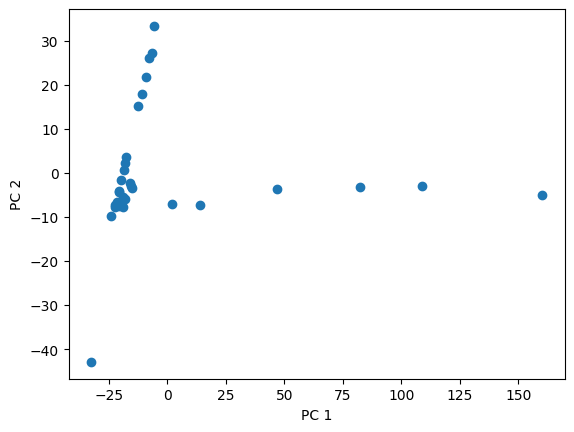

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.transform(X_test_std)

plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1])
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.show()

**Clustering Analysis**

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=3, random_state=0)  # kmeans model with given number of clusters

kmeans.fit(X_train_std)        # fit the model to the data -- data shiould be standardized or normalized

print('Cluster membership:')
print(kmeans.labels_)          # cluster labels
#print(kmeans.predict(X_train_std))

print('\nNumber of samples in clusters:')
print(pd.Series(kmeans.labels_).value_counts())

centers = kmeans.cluster_centers_
print('\nCluster centers (means):')
for (i,c) in enumerate(centers):
    print('Cluster', i, ':', c)

Cluster membership:
[1 1 1 2 2 1 1 1 2 2 2 1 1 1 1 2 0 0 1 1 1 1 1 0 1 1 1 0 1 1]

Number of samples in clusters:
1    20
2     6
0     4
Name: count, dtype: int64

Cluster centers (means):
Cluster 0 : [ 1.01   2.     2.266  2.266  2.266  2.266  2.266  2.266  2.266  2.266  2.266  2.266  2.266  2.269  2.274  2.278  2.281  2.284  2.284  2.283  2.28   2.279  2.278  2.278  2.278  2.279  2.279  2.281
  2.281  2.281  2.281  2.28   2.279  2.281  2.282  2.284  2.284  2.284  2.283  2.282  2.282  2.283  2.283  2.284  2.284  2.285  2.287  2.288  2.287  2.285  2.284  2.285  2.286  2.287  2.288  2.289
  2.289  2.29   2.289  2.289  2.288  2.288  2.288  2.288  2.289  2.291  2.291  2.29   2.289  2.287  2.287  2.287  2.287  2.289  2.29   2.291  2.29   2.29   2.29   2.289  2.288  2.289  2.29   2.29
  2.291  2.29   2.289  2.289  2.29   2.289  2.288  2.29   2.29   2.29   2.291  2.29   2.29   2.29   2.289  2.29   2.29   2.289  2.289  2.29   2.29   2.289  2.288  2.287  2.287  2.288  2.288  2.289
  2.289  2.

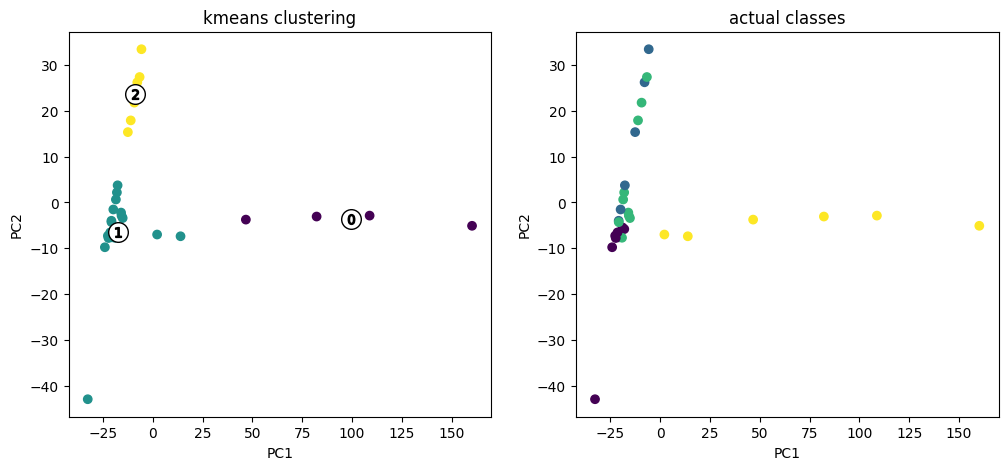

Performance metrics:
  Within-cluster SSE: 11206.532368525186
  Silhouette score:   0.5531189406775228


In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1, xlabel='PC1', ylabel='PC2', title='kmeans clustering')
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c = kmeans.labels_)  # Color the clusters
plt.scatter(pca.transform(centers)[:,0], pca.transform(centers)[:,1], marker='o', c="white", alpha=1, s=200, edgecolor='k')
for i, c_val in enumerate(centers):
    plt.scatter(pca.transform(c_val.reshape(1,-1))[:,0], pca.transform(c_val.reshape(1,-1))[:,1], marker='$%d$' % i, alpha=1, s=50, edgecolor='k')

plt.subplot(1,2,2, xlabel='PC1', ylabel='PC2', title='actual classes')
# Convert y_train string labels to numerical categories for coloring
y_train_numerical = pd.factorize(y_train)[0]
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c = y_train_numerical)         # Color the actual classes
plt.show()

print('Performance metrics:')
print('  Within-cluster SSE:',  kmeans.inertia_)   # Sum of squared distances of samples to their closest cluster center
print('  Silhouette score:  ',  silhouette_score(X_train_std, kmeans.labels_))